<a href="https://colab.research.google.com/github/Caio-R-C/RemoteSensingStudies/blob/main/visualizacao_pseudo3d_vtk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualização Avançada do Modelo Pseudo-3D (VTK)
### Mestrado - Fazenda Água Limpa (FAL) | Investigação de Aquífero Fraturado

Este notebook processa e renderiza a malha volumétrica 3D da inversão do ResIPy, fornecendo visualizações especializadas para a dissertação:
1. **Modelo de Camadas Horizontais Empilhadas (*Stacked Depth Slices*)**: Fatias em cotas sucessivas de profundidade visualizadas simultaneamente em perspectiva 3D (similar ao modelo da literatura).
2. **Painel de Cercas (*Fence Diagram*) com Isosuperfície 3D**: Seções verticais simultâneas (ao longo dos perfis P1-P4 e/ou transversais) integradas a corpos tridimensionais (isosuperfícies de resistividade) que cortam os perfis.
3. **Isolamento Volumétrico (*Thresholding*) do Aquífero Fraturado**: Delineamento da zona saturada/alterada de baixa a moderada resistividade cortando a rocha sã.
4. **Exportação Tabular Georreferenciada (CSV)**: Coordenadas $(X, Y, Z)$ com resistividade real para correlação com poços e uso em SIG (QGIS/ArcGIS).

**Arquivos de entrada:**
* `3Dfrom2Dlines.vtk`: Malha tetraédrica volumétrica 3D invertida.
* `eletrodos.vtk`: Posições dos eletrodos.


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pyvista as pv

# Configura renderização no Jupyter ('static' garante exibição de imagens limpas e reproduzíveis)
try:
    pv.set_jupyter_backend('static')
except Exception:
    pass

# Diretório dos dados da inversão Pseudo-3D
PATH_DIR = r"C:\Faculdade\MESTRADO\DADOS - FAL\PERFIS - RESISTIVIDADE\DADOS - P1, P2, P3 e P4\pseudo 3d - inversão"
PATH_VTK_MESH = os.path.join(PATH_DIR, "3Dfrom2Dlines.vtk")
PATH_VTK_ELEC = os.path.join(PATH_DIR, "eletrodos.vtk")

print("Verificação dos arquivos de entrada:")
print(f"  • Malha 3D (.vtk):    {'OK' if os.path.exists(PATH_VTK_MESH) else 'NÃO ENCONTRADO'} -> {PATH_VTK_MESH}")
print(f"  • Eletrodos (.vtk):   {'OK' if os.path.exists(PATH_VTK_ELEC) else 'NÃO ENCONTRADO'} -> {PATH_VTK_ELEC}")


Verificação dos arquivos de entrada:
  • Malha 3D (.vtk):    OK -> C:\Faculdade\MESTRADO\DADOS - FAL\PERFIS - RESISTIVIDADE\DADOS - P1, P2, P3 e P4\pseudo 3d - inversão\3Dfrom2Dlines.vtk
  • Eletrodos (.vtk):   OK -> C:\Faculdade\MESTRADO\DADOS - FAL\PERFIS - RESISTIVIDADE\DADOS - P1, P2, P3 e P4\pseudo 3d - inversão\eletrodos.vtk


In [ ]:
# Carregamento da malha 3D e eletrodos
mesh = pv.read(PATH_VTK_MESH)
elec = pv.read(PATH_VTK_ELEC)

# Conversão dos dados de células para pontos (permite cálculo de isosuperfícies suaves)
mesh_pt = mesh.cell_data_to_point_data()

xmin, xmax, ymin, ymax, zmin, zmax = mesh.bounds

print("="*68)
print("  DIAGNÓSTICO ESPACIAL DO BLOCO 3D (UTM / COTA)")
print("="*68)
print(f"  • Células volumétricas: {mesh.n_cells:,}")
print(f"  • Vértices da malha:    {mesh.n_points:,}")
print(f"  • Coordenadas X (Leste UTM): {xmin:,.1f} m a {xmax:,.1f} m (Extensão: {xmax-xmin:.1f} m)")
print(f"  • Coordenadas Y (Norte UTM): {ymin:,.1f} m a {ymax:,.1f} m (Extensão: {ymax-ymin:.1f} m)")
print(f"  • Coordenadas Z (Profundidade): {zmin:,.1f} m a {zmax:,.1f} m (Investigação: {abs(zmin):.1f} m)")
print(f"  • Eletrodos identificados: {elec.n_points} (4 linhas de 56 eletrodos)")
print("="*68)


  DIAGNÓSTICO ESPACIAL DO BLOCO 3D (UTM / COTA)
  • Células volumétricas: 307,426
  • Vértices da malha:    54,620
  • Coordenadas X (Leste UTM): 184,003.0 m a 185,469.7 m (Extensão: 1466.7 m)
  • Coordenadas Y (Norte UTM): 8,230,571.8 m a 8,231,713.7 m (Extensão: 1141.9 m)
  • Coordenadas Z (Profundidade): -566.6 m a 0.0 m (Investigação: 566.6 m)
  • Eletrodos identificados: 224 (4 linhas de 56 eletrodos)


C:\Users\caio_\AppData\Local\Temp\ipykernel_27692\645529172.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(log_res, vert=False, patch_artist=True, boxprops=dict(facecolor='#aec7e8'))


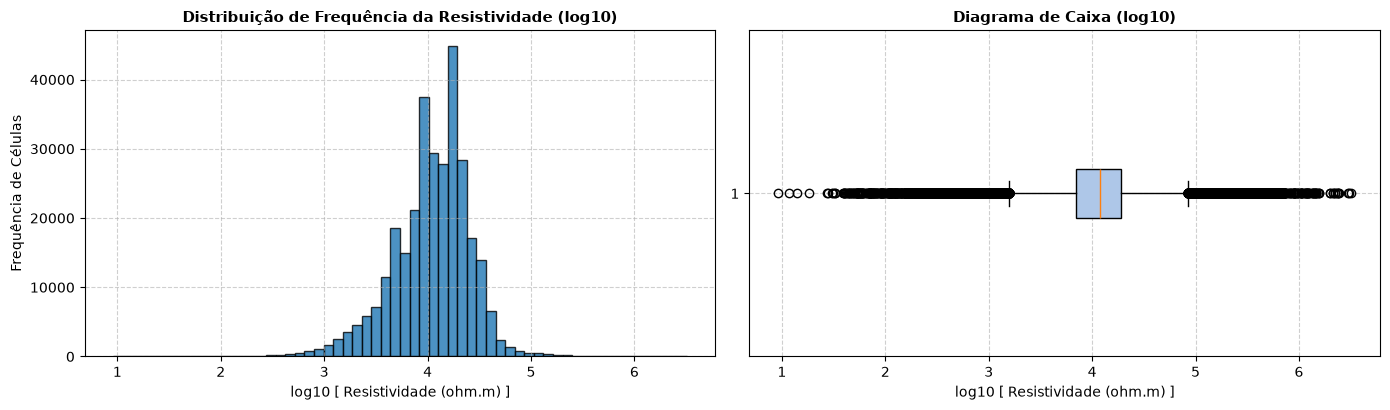

Resistividade mínima: 9.13 ohm.m  (Zonas condutivas / aquífero fraturado)
Resistividade mediana: 11828.69 ohm.m
Resistividade máxima: 3209152.89 ohm.m  (Rocha cristalina sã / quartzito)


In [ ]:
res = mesh.cell_data['Resistivity(ohm.m)']
log_res = mesh.cell_data['Resistivity(log10)']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# Histograma da Resistividade
axes[0].hist(log_res, bins=60, color='#1f77b4', edgecolor='black', alpha=0.8)
axes[0].set_title("Distribuição de Frequência da Resistividade (log10)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("log10 [ Resistividade (ohm.m) ]")
axes[0].set_ylabel("Frequência de Células")
axes[0].grid(True, linestyle='--', alpha=0.6)

# Boxplot
axes[1].boxplot(log_res, vert=False, patch_artist=True, boxprops=dict(facecolor='#aec7e8'))
axes[1].set_title("Diagrama de Caixa (log10)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("log10 [ Resistividade (ohm.m) ]")
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Resistividade mínima: {res.min():.2f} ohm.m  (Zonas condutivas / aquífero fraturado)")
print(f"Resistividade mediana: {np.median(res):.2f} ohm.m")
print(f"Resistividade máxima: {res.max():.2f} ohm.m  (Rocha cristalina sã / quartzito)")


Gerando modelo de camadas empilhadas em 8 níveis...


C:\Users\caio_\AppData\Local\Temp\ipykernel_27692\806610759.py:38: UserWarning: No vector-like data to use for orient. orient will be set to False.
  esferas_eletrodos = elec.glyph(scale=False, geom=pv.Sphere(radius=7.0))


✅ Imagem do modelo de camadas salva em: C:\Faculdade\MESTRADO\DADOS - FAL\PERFIS - RESISTIVIDADE\DADOS - P1, P2, P3 e P4\pseudo 3d - inversão\modelo_camadas_empilhadas_3d.png


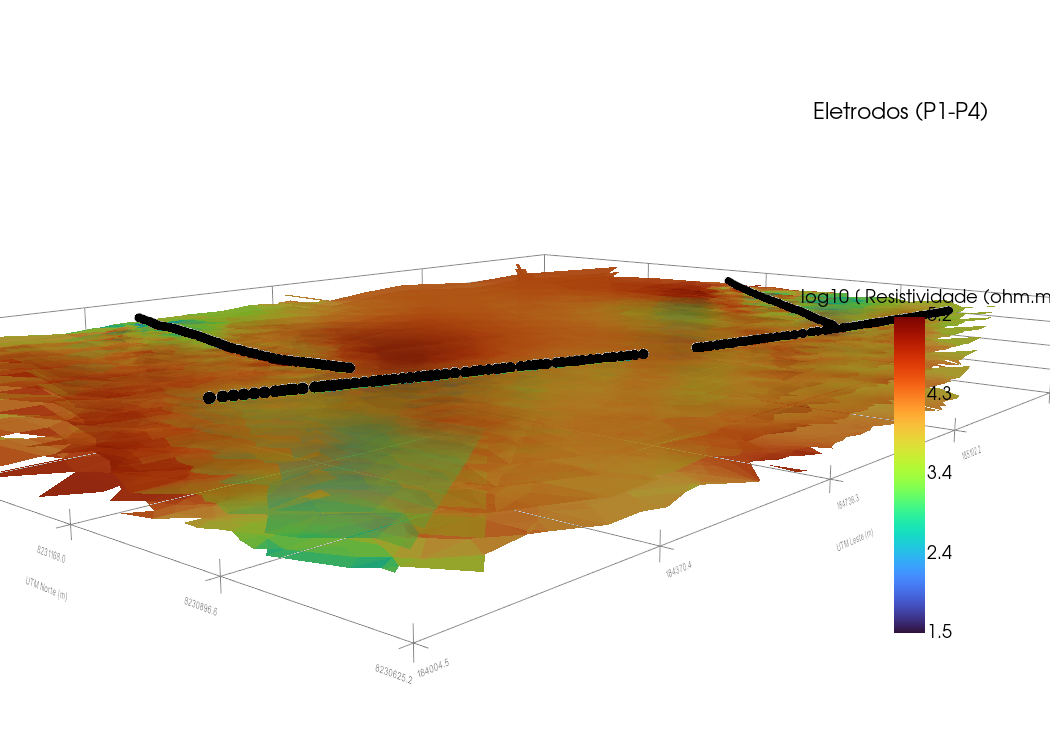

In [ ]:
# ==============================================================================
# MODELO DE CAMADAS HORIZONTAIS EMPILHADAS (STACKED HORIZONTAL SLICES)
# Similar à figura da esquerda: exibe fatias em profundidades sucessivas em 3D
# ==============================================================================

# Definição das cotas/profundidades de amostragem (metros)
profundidades_camadas = [-5, -15, -25, -40, -60, -85, -115, -150]

print(f"Gerando modelo de camadas empilhadas em {len(profundidades_camadas)} níveis...")

camadas_stack = pv.MultiBlock()
for z_prof in profundidades_camadas:
    sl = mesh.slice(normal='z', origin=(0, 0, z_prof))
    if sl.n_cells > 0:
        camadas_stack.append(sl)

# Criação da cena 3D
plotter_camadas = pv.Plotter(window_size=[1050, 750])

# Adiciona cada camada com a escala contínua de cores
plotter_camadas.add_mesh(
    camadas_stack,
    scalars='Resistivity(log10)',
    cmap='turbo',
    clim=[1.5, 5.2],  # de ~30 ohm.m até ~160.000 ohm.m
    show_edges=False,
    opacity=0.95,
    scalar_bar_args={
        'title': 'log10 [ Resistividade (ohm.m) ]',
        'vertical': True,
        'position_x': 0.85,
        'position_y': 0.15,
        'fmt': '%.1f'
    }
)

# Adiciona os eletrodos na superfície
esferas_eletrodos = elec.glyph(scale=False, geom=pv.Sphere(radius=7.0))
plotter_camadas.add_mesh(esferas_eletrodos, color='black', render_points_as_spheres=True, label='Eletrodos P1-P4')

# Configuração de eixos UTM e iluminação
plotter_camadas.show_grid(color='gray', font_size=8, xtitle='UTM Leste (m)', ytitle='UTM Norte (m)', ztitle='Cota (m)')
plotter_camadas.add_legend([['Eletrodos (P1-P4)', 'black']])
plotter_camadas.camera_position = [(183200, 8229800, 300), (184700, 8231100, -70), (0, 0, 1)]

# Salva imagem para a dissertação
img_camadas = os.path.join(PATH_DIR, "modelo_camadas_empilhadas_3d.png")
plotter_camadas.screenshot(img_camadas)
print(f"✅ Imagem do modelo de camadas salva em: {img_camadas}")

plotter_camadas.show()


Calculando Isosuperfície 3D para 2000 ohm.m (log10 = 3.30)...


C:\Users\caio_\AppData\Local\Temp\ipykernel_27692\3832162455.py:60: UserWarning: No vector-like data to use for orient. orient will be set to False.
  plotter_cercas.add_mesh(elec.glyph(scale=False, geom=pv.Sphere(radius=6.0)), color='black')


✅ Imagem do painel de cercas salva em: C:\Faculdade\MESTRADO\DADOS - FAL\PERFIS - RESISTIVIDADE\DADOS - P1, P2, P3 e P4\pseudo 3d - inversão\painel_cercas_isosuperficie_3d.png


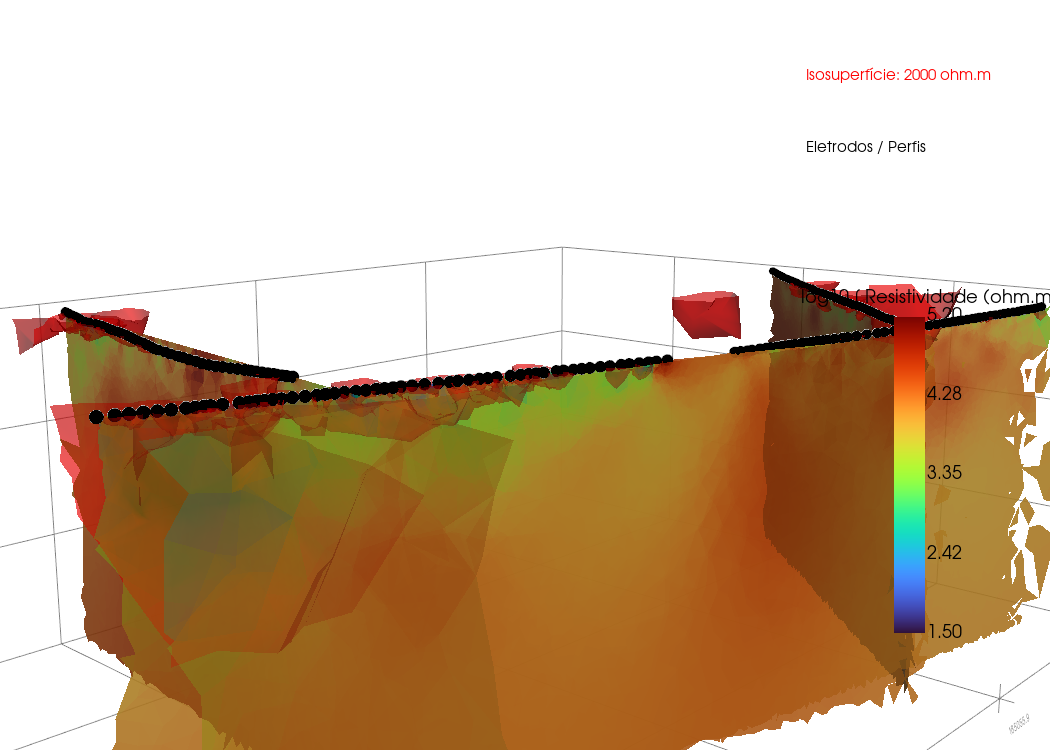

In [ ]:
# ==============================================================================
# PAINEL DE CERCAS (FENCE DIAGRAM) INTEGRADO COM ISOSUPERFÍCIE 3D
# Similar à figura da direita: seções verticais combinadas com corpo anômalo 3D
# ==============================================================================

# 1. Gerar seções verticais ao longo das 4 linhas reais de eletrorresistividade
pts = elec.points
secoes_verticais = pv.MultiBlock()

for i in range(4):
    p1 = pts[i * 56]
    p2 = pts[(i + 1) * 56 - 1]
    dx = p2[0] - p1[0]
    dy = p2[1] - p1[1]
    normal = (-dy, dx, 0)
    origin = (p1 + p2) / 2
    sl = mesh.slice(normal=normal, origin=origin)
    secoes_verticais.append(sl)

# 2. Gerar a Isosuperfície 3D do corpo de interesse (alvo de baixa/moderada resistividade)
# Exemplo: Fraturas/alteração saturada com Resistividade <= 2.000 ohm.m (log10 = 3.30)
RES_ISOSUPERFICIE_OHM = 2000.0
log_iso = np.log10(RES_ISOSUPERFICIE_OHM)

print(f"Calculando Isosuperfície 3D para {RES_ISOSUPERFICIE_OHM:.0f} ohm.m (log10 = {log_iso:.2f})...")
isosuperficie = mesh_pt.contour(
    isosurfaces=[log_iso],
    scalars='Resistivity(log10)'
)

# 3. Montagem da visualização integrada (Seções verticais + Isosuperfície vermelha)
plotter_cercas = pv.Plotter(window_size=[1050, 750])

# Adiciona as seções verticais dos perfis
plotter_cercas.add_mesh(
    secoes_verticais,
    scalars='Resistivity(log10)',
    cmap='turbo',
    clim=[1.5, 5.2],
    opacity=0.90,
    show_edges=False,
    scalar_bar_args={
        'title': 'log10 [ Resistividade (ohm.m) ]',
        'vertical': True,
        'position_x': 0.85,
        'position_y': 0.15
    }
)

# Adiciona a Isosuperfície em vermelho (destacando o corpo aquífero/fraturado 3D)
plotter_cercas.add_mesh(
    isosuperficie,
    color='red',
    opacity=0.65,
    smooth_shading=True,
    label=f'Isosuperfície ({RES_ISOSUPERFICIE_OHM:.0f} ohm.m)'
)

# Adiciona as linhas dos perfis no topo
plotter_cercas.add_mesh(elec.glyph(scale=False, geom=pv.Sphere(radius=6.0)), color='black')

plotter_cercas.show_grid(color='gray', font_size=8, xtitle='UTM Leste', ytitle='UTM Norte', ztitle='Cota (m)')
plotter_cercas.add_legend([
    [f'Isosuperfície: {RES_ISOSUPERFICIE_OHM:.0f} ohm.m', 'red'],
    ['Eletrodos / Perfis', 'black']
])
plotter_cercas.camera_position = [(183500, 8230000, 250), (184700, 8231100, -60), (0, 0, 1)]

# Salva imagem de alta resolução para a dissertação
img_cercas = os.path.join(PATH_DIR, "painel_cercas_isosuperficie_3d.png")
plotter_cercas.screenshot(img_cercas)
print(f"✅ Imagem do painel de cercas salva em: {img_cercas}")

plotter_cercas.show()


✅ Imagem salva: C:\Faculdade\MESTRADO\DADOS - FAL\PERFIS - RESISTIVIDADE\DADOS - P1, P2, P3 e P4\pseudo 3d - inversão\fatias_paralelas_isosuperficie_3d.png


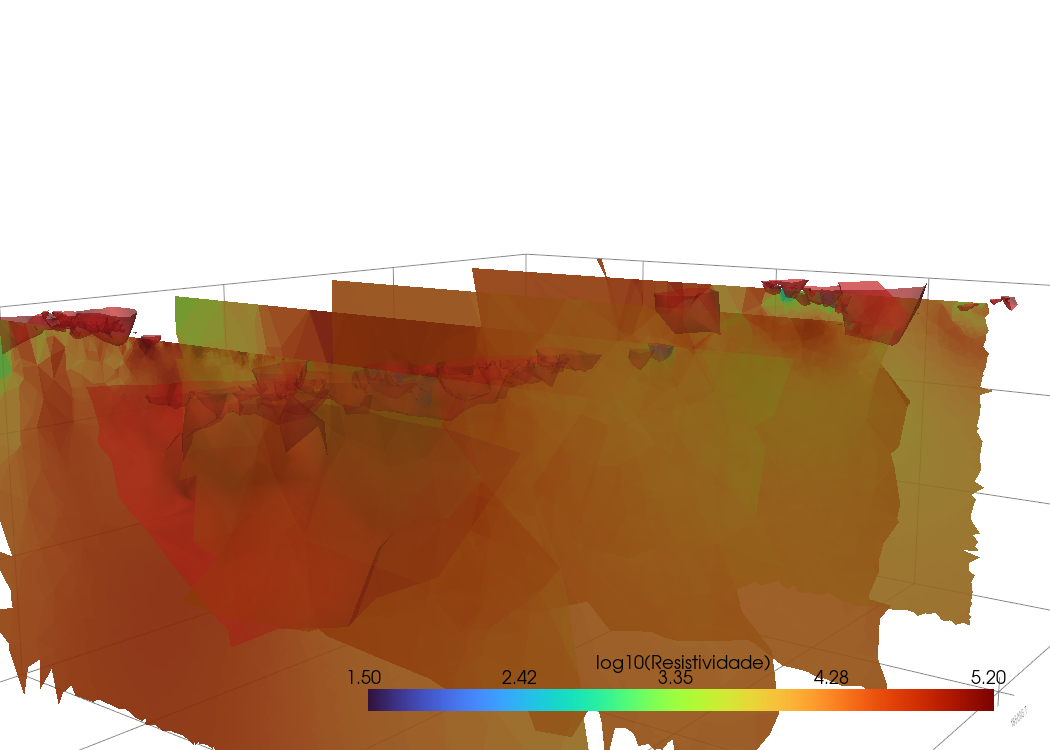

In [ ]:
# ==============================================================================
# PAINEL DE FATIAS VERTICAIS PARALELAS COM ISOSUPERFÍCIE
# Fatias verticais regulares cortando a área transversalmente
# ==============================================================================

# Gera 6 fatias verticais paralelas ao longo do eixo X (ou Y)
fatias_paralelas = mesh.slice_along_axis(n=6, axis='x')

plotter_grid = pv.Plotter(window_size=[1050, 750])

plotter_grid.add_mesh(
    fatias_paralelas,
    scalars='Resistivity(log10)',
    cmap='turbo',
    clim=[1.5, 5.2],
    opacity=0.92,
    scalar_bar_args={'title': 'log10(Resistividade)'}
)

plotter_grid.add_mesh(
    isosuperficie,
    color='#d62728', # Vermelho vivo
    opacity=0.70,
    smooth_shading=True,
    label=f'Corpo Condutivo ({RES_ISOSUPERFICIE_OHM:.0f} ohm.m)'
)

plotter_grid.show_grid(color='gray', font_size=8)
plotter_grid.camera_position = [(183400, 8230100, 200), (184700, 8231100, -70), (0, 0, 1)]

img_grid = os.path.join(PATH_DIR, "fatias_paralelas_isosuperficie_3d.png")
plotter_grid.screenshot(img_grid)
print(f"✅ Imagem salva: {img_grid}")

plotter_grid.show()


Filtrando células com Resistividade <= 2000 ohm.m (log10 <= 3.30)...
Células do aquífero/fraturas: 12,555 de 307,426


C:\Users\caio_\AppData\Local\Temp\ipykernel_27692\2543676570.py:28: UserWarning: No vector-like data to use for orient. orient will be set to False.
  p_vol.add_mesh(elec.glyph(scale=False, geom=pv.Sphere(radius=7.0)), color='black')


✅ Imagem do volume sólido salva em: C:\Faculdade\MESTRADO\DADOS - FAL\PERFIS - RESISTIVIDADE\DADOS - P1, P2, P3 e P4\pseudo 3d - inversão\volume_aquifero_solido_3d.png


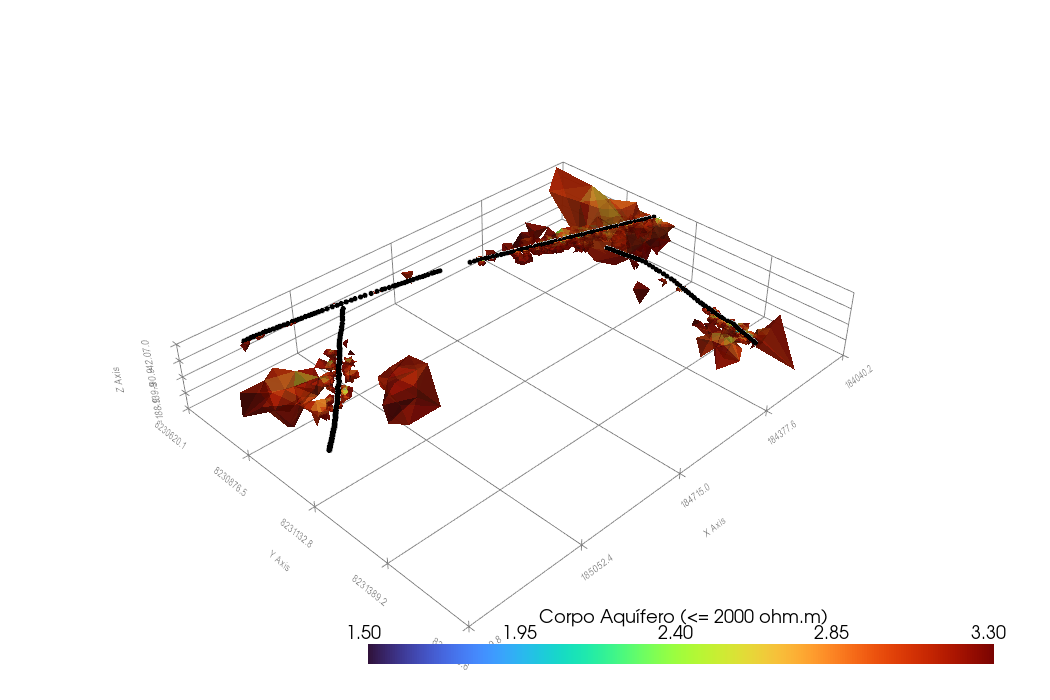

In [ ]:
# ==============================================================================
# ISOLAMENTO VOLUMÉTRICO COMPLETO DO AQUÍFERO (THRESHOLDING)
# ==============================================================================

LIMIAR_MAX_OHM = 2000.0
log_limiar = np.log10(LIMIAR_MAX_OHM)

print(f"Filtrando células com Resistividade <= {LIMIAR_MAX_OHM:.0f} ohm.m (log10 <= {log_limiar:.2f})...")

# Mantém apenas as células sólidas que atendem ao critério de resistividade
aquifero_solido = mesh.threshold(
    value=[mesh.cell_data['Resistivity(log10)'].min(), log_limiar],
    scalars='Resistivity(log10)'
)

print(f"Células do aquífero/fraturas: {aquifero_solido.n_cells:,} de {mesh.n_cells:,}")

p_vol = pv.Plotter(window_size=[1050, 700])
p_vol.add_mesh(
    aquifero_solido,
    scalars='Resistivity(log10)',
    cmap='turbo',
    clim=[1.5, log_limiar],
    opacity=0.85,
    scalar_bar_args={'title': f'Corpo Aquífero (<= {LIMIAR_MAX_OHM:.0f} ohm.m)'}
)

p_vol.add_mesh(elec.glyph(scale=False, geom=pv.Sphere(radius=7.0)), color='black')
p_vol.show_grid(color='gray', font_size=8)
p_vol.camera_position = 'iso'

img_vol = os.path.join(PATH_DIR, "volume_aquifero_solido_3d.png")
p_vol.screenshot(img_vol)
print(f"✅ Imagem do volume sólido salva em: {img_vol}")

p_vol.show()


In [ ]:
# ==============================================================================
# EXPORTAÇÃO TABULAR (CSV) PARA SIG / QGIS / CORRELAÇÃO COM POÇOS
# ==============================================================================

print("Extraindo centroides e propriedades de cada célula da malha 3D...")
centros = mesh.cell_centers().points

df_3d = pd.DataFrame({
    'X_UTM': centros[:, 0],
    'Y_UTM': centros[:, 1],
    'Z_Cota': centros[:, 2],
    'Resistividade_ohm_m': mesh.cell_data['Resistivity(ohm.m)'],
    'Resistividade_log10': mesh.cell_data['Resistivity(log10)'],
    'Sensibilidade_log10': mesh.cell_data['Sensitivity_map(log10)']
})

arquivo_csv = os.path.join(PATH_DIR, "pseudo3d_resultados_celulas.csv")
df_3d.to_csv(arquivo_csv, index=False)

print(f"✅ Tabela CSV gerada com sucesso!")
print(f"   Arquivo: {arquivo_csv}")
print(f"   Total de registros: {len(df_3d):,}")
display(df_3d.head(10))
